# Predicción dinámica de siniestros en carreteras chilenas
## Presentación Técnica Final · Etapa III

**Integrantes:** Diego Franco, Vicente González, Martín Mora, Cristóbal Rivera y Máximo Urrutia.
**Profesor:** Andrés Jiménez B. · **Asignatura:** Ciencia de Datos · **Fecha:** noviembre de 2026.

Nuestro proyecto estudia cómo cambia la frecuencia de siniestros a lo largo de la
Ruta 5 Sur según la ubicación, el horario, el calendario y la lluvia. Queremos
estimar cuántos eventos esperar y evaluar si esa información ayuda a priorizar la
vigilancia mejor que un mapa histórico fijo.

El notebook recorre preparación, exploración, entrenamiento, validación temporal,
comparación e interpretación. Todas las tablas de evaluación y las conclusiones
finales se calculan con los modelos entrenados durante esta ejecución. Los datos
se mantienen en 2020–2024; el año 2024 se declara evaluación histórica reutilizada,
pues ya se había inspeccionado en etapas anteriores.

### Cómo ejecutar la entrega

El archivo incorpora el código y las fuentes necesarias. No requiere clonar GitHub,
subir un ZIP adicional ni disponer de nuestros modelos guardados. La primera celda
prepara una carpeta temporal y verifica sus archivos. Se necesita Python 3.11–3.13
y CPU; la instalación inicial de bibliotecas requiere internet si faltan versiones.

En Colab, ejecutar primero esa celda. Si solicita reiniciar Python después de
instalar dependencias, reiniciar la sesión sin eliminar la máquina y volver a ejecutar
desde arriba. Después, usar **Ejecutar todas**. La comparación completa realiza
60 ajustes de búsqueda/validación más el reajuste final y puede tardar decenas de
minutos, según los recursos de la sesión. No se sustituye ese entrenamiento por tablas
precargadas. Las salidas quedan dentro de la carpeta temporal de esta ejecución.

El bloque compacto de preparación contiene fuentes y datos comprimidos, sin joblib
preajustados. El código extraído es legible dentro de `codigo/`. En las secciones
siguientes explicamos y utilizamos sus funciones. El historial del repositorio
conserva las contribuciones del equipo y la asistencia de herramientas declarada.

In [1]:
#@title Preparar los datos y el código de la entrega
import base64, hashlib, io, json, os, sys, tempfile, zipfile, subprocess
from pathlib import Path
import importlib.metadata as metadata
PAQUETE_B64 = "..."
paquete = base64.b64decode(PAQUETE_B64)
assert hashlib.sha256(paquete).hexdigest() == "e2b1b2c0feca41d00f8a641749586a772492b860b5a506bedf1a6136a0e6c203"
RAIZ = Path(tempfile.mkdtemp(prefix="siniestros_entrega_"))
with zipfile.ZipFile(io.BytesIO(paquete)) as archivo:
    for nombre in archivo.namelist():
        if Path(nombre).is_absolute() or ".." in Path(nombre).parts:
            raise ValueError("Ruta no admitida en el paquete")
    archivo.extractall(RAIZ)
manifest = json.loads((RAIZ / "MANIFIESTO_ENTREGA.json").read_text())
for nombre, sha in manifest["archivos_sha256"].items():
    assert hashlib.sha256((RAIZ / nombre).read_bytes()).hexdigest() == sha, nombre
assert manifest["incluye_modelos_preajustados"] is False
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/siniestros-matplotlib")
if not (3, 11) <= sys.version_info[:2] <= (3, 13):
    raise RuntimeError("Seleccionar Python 3.11–3.13 para las versiones de esta entrega")
esperadas = {"numpy": ("numpy", "2.2.3"), "pandas": ("pandas", "2.2.3"),
    "scipy": ("scipy", "1.14.1"), "scikit-learn": ("sklearn", "1.6.1"),
    "matplotlib": ("matplotlib", "3.9.4"), "joblib": ("joblib", "1.6.0"), "xlrd": ("xlrd", "2.0.1")}
cambios=[]
for nombre,(modulo,version) in esperadas.items():
    try: actual=metadata.version(nombre)
    except metadata.PackageNotFoundError: actual=None
    if actual != version: cambios.append((nombre,modulo))
if cambios:
    cargados=[m for _,m in cambios if m in sys.modules]
    subprocess.run([sys.executable,"-m","pip","install","--quiet","-r","requirements-colab.txt"],check=True)
    if cargados:
        raise RuntimeError("Dependencias instaladas. Reinicia Python sin eliminar la sesión y vuelve a ejecutar desde arriba.")
print("Fuentes verificadas:",len(manifest["archivos_sha256"]),"· modelos precargados: ninguno")
print("Directorio de esta ejecución:",RAIZ)

Fuentes verificadas: 26 · modelos precargados: ninguno
Directorio de esta ejecución: /tmp/siniestros_entrega_s9236q25


## 1. Pregunta y enfoque metodológico

La pregunta es: **¿qué tramos y horas concentran más siniestros esperados y cuánto
mejora su priorización al incorporar contexto temporal, lluvia y circulación?**
La unidad de análisis es un tramo de 5 km durante una hora civil. La respuesta es
un conteo, que puede valer cero, uno o más.

Seguimos las etapas de comprensión del problema, comprensión y preparación de los
datos, modelado y evaluación de CRISP-DM. Elegimos regresión de conteos para conservar
la pregunta de cantidad y evaluamos también la capacidad de ordenar tramos. Una
segunda evaluación convierte los conteos en “al menos un siniestro” para interpretar
accuracy, precisión, recall, F1 y las curvas ROC/PR; ese diagnóstico auxiliar no
cambia el objetivo principal ni el criterio de selección.

In [2]:
import proyecto
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, JSON
from io import BytesIO
from threadpoolctl import threadpool_limits
from datos_ruta5 import cargar_eventos, referencia_entrenamiento, grilla_civil, exposicion_civil
from datos_modelado import cuarentena_espacial

def mostrar(fig):
    b=BytesIO();fig.savefig(b,format="png",dpi=130,bbox_inches="tight")
    display(Image(data=b.getvalue()));plt.close(fig)

eventos_km, audit_fuente = cargar_eventos()
eventos, cuarentena = cuarentena_espacial(eventos_km)
referencia = referencia_entrenamiento(eventos)
tiempo, y_base, fuera = grilla_civil(eventos,referencia.tramo.to_numpy())
expo = exposicion_civil(tiempo)
assert len(eventos)==14420 and len(referencia)==255 and fuera==0
assert y_base[:,expo==0].sum()==0
print("Población preparada:",len(eventos),"eventos;",len(referencia),"tramos")

Población preparada: 14420 eventos; 255 tramos


## 2. Diseño de la comparación y entrenamiento

Entrenamos Poisson, Gradient Boosting y Random Forest. M0 (tasa uniforme) y M1
(mapa espacial) son nuestras referencias. Cada familia incorpora calendario y lluvia;
en los 153 tramos cubiertos se añade el proxy DGC para medir su aporte en la misma
población. Los híbridos usan respaldo sin flujo donde no hay información.

La validación respeta el orden del tiempo: entrenamiento 2020–2021/prueba 2022;
2020–2022/prueba 2023; 2020–2023/prueba 2024. En 2022 usamos una configuración simple
prefijada; para 2023 elegimos con 2022 y para 2024 con 2022/2023. El modelo final se
selecciona con captura global al 5 % promediada en 2022/2023 y preferencia por sencillez
a 0,1 puntos porcentuales del mejor promedio. No se elige usando F1 o resultados de 2024.

La celda siguiente ejecuta el entrenamiento completo. Se muestran los ajustes y sus
resultados conforme terminan; cada llamada del entrenador utiliza
`ModeloConteo(familia, variante, parametros).fit(atributos_train, conteos_train, exposicion_train)`.
Los parámetros, años usados y diagnósticos quedan registrados en los archivos de esta corrida.

In [3]:
# Ajustar todos los modelos y evaluar con el protocolo temporal descrito.
# No se cargan joblib ni métricas de entregas anteriores.
from time import perf_counter
SALIDA = RAIZ / "resultados/ejecucion_notebook"
inicio_ajuste = perf_counter()
proceso = subprocess.Popen([sys.executable,"proyecto.py","experimento_entrega","--salida",str(SALIDA)],
    cwd=RAIZ,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
for linea in proceso.stdout:
    print(linea,end="",flush=True)
if proceso.wait()!=0:
    raise RuntimeError("El entrenamiento no terminó correctamente; revisar el último mensaje")
minutos_ajuste = (perf_counter()-inicio_ajuste)/60
metricas = pd.read_csv(SALIDA/"metricas.csv")
bootstrap = pd.read_csv(SALIDA/"bootstrap.csv")
seleccion = pd.read_csv(SALIDA/"seleccion_temporal.csv")
busqueda = pd.read_csv(SALIDA/"busqueda_temporal.csv")
conteo_extra = pd.read_csv(SALIDA/"metricas_conteo_adicionales.csv")
binarias = pd.read_csv(SALIDA/"metricas_binarias.csv")
curvas_binarias = pd.read_csv(SALIDA/"curvas_binarias.csv")
auditoria = json.loads((SALIDA/"auditoria.json").read_text())
reajuste = json.loads((SALIDA/"reajuste.json").read_text())
recalibracion = pd.read_csv(SALIDA/"recalibracion_candidato.csv")
assert len(metricas)==114 and len(busqueda)==60 and len(seleccion)==36
print(f"Entrenamiento y evaluación completados en {minutos_ajuste:.1f} minutos.")

[{"anio": 2020, "tramos_con_flujo": 153, "tramos_total": 255, "siniestros_con_flujo": 1149, "siniestros_total": 2295, "porcentaje_eventos": 50.06535947712418}, {"anio": 2021, "tramos_con_flujo": 153, "tramos_total": 255, "siniestros_con_flujo": 1669, "siniestros_total": 3288, "porcentaje_eventos": 50.76034063260341}, {"anio": 2022, "tramos_con_flujo": 153, "tramos_total": 255, "siniestros_con_flujo": 1872, "siniestros_total": 3369, "porcentaje_eventos": 55.565449688334816}, {"anio": 2023, "tramos_con_flujo": 153, "tramos_total": 255, "siniestros_con_flujo": 1577, "siniestros_total": 2863, "porcentaje_eventos": 55.08208173244848}, {"anio": 2024, "tramos_con_flujo": 153, "tramos_total": 255, "siniestros_con_flujo": 1491, "siniestros_total": 2605, "porcentaje_eventos": 57.23608445297505}]


2022 ruta_completa Poisson_clima cfg0: captura=19.561%, 12.6s


2022 ruta_completa Poisson_clima cfg1: captura=19.590%, 29.2s


2022 ruta_completa GradientBoosting_clima cfg0: captura=19.501%, 12.2s


2022 ruta_completa GradientBoosting_clima cfg1: captura=17.364%, 21.9s


2022 ruta_completa RandomForest_clima cfg0: captura=15.554%, 51.5s


... (103 outputs left out)

  ]


}


ENTRENAMIENTO_ENTREGA_CORRECTO: 2080.0 s


Entrenamiento y evaluación completados en 34.7 minutos.


## 3. Datos utilizados y correcciones de calidad

Volvemos sobre los datos de entrada para interpretar qué aprendieron los modelos.
CONASET aporta los siniestros; ERA5, la precipitación horaria; el calendario indica
la posición dentro de períodos festivos, y los anexos DGC describen circulación por
contrato y trimestre. Conservamos las unidades de cada fuente y verificamos sus
hashes al preparar el notebook.

El archivo de CONASET contiene otras variantes de Ruta 5. Nuestro filtro conserva
exclusivamente `RUTA 5 SUR`, descarta cinco kilómetros no utilizables y pone en
cuarentena cinco discordancias importantes entre kilometraje y coordenadas.
No corregimos esas ubicaciones por suposición. La referencia espacial se construye
solo con 2020–2021 y permanece fija para los años de prueba.

In [4]:
display(pd.DataFrame({"Etapa":["Ruta 5 Sur en la fuente","Después del filtro de km","Después de cuarentena"],
    "Eventos":[audit_fuente["registros_ruta"],len(eventos_km),len(eventos)]}))
display(cuarentena[["ID","anio","km","distancia_referencia_km","motivo"]].round(2))
campos=["ID","FECHA","Hora_aprox","Ruta","Ubicación","Latitud","longitud"]
display(eventos[campos].isna().sum().rename("Faltantes en campos críticos").to_frame())
assert eventos.ID.is_unique and eventos.hora.between(0,23).all()
assert (eventos.TOTAL_LESI==eventos[["GRAVES","MENOS_GRAV","LEVES"]].sum(axis=1)).all()
print("No se eliminan eventos graves por ser extremos: se conservan los conteos legítimos.")

,Etapa,Eventos
0,Ruta 5 Sur en la fuente,14430
1,Después del filtro de km,14425
2,Después de cuarentena,14420


,ID,anio,km,distancia_referencia_km,motivo
4106,1334758,2021,7.4,667.87,Kilometraje y coordenadas incompatibles; ubica...
7718,1407830,2021,1.2,1037.47,Kilometraje y coordenadas incompatibles; ubica...
7933,1408146,2021,1.2,1037.47,Kilometraje y coordenadas incompatibles; ubica...
8007,1407806,2021,1.2,1037.47,Kilometraje y coordenadas incompatibles; ubica...
9384,1429192,2022,40.1,332.94,Kilometraje y coordenadas incompatibles; ubica...


,Faltantes en campos críticos
ID,0
FECHA,0
Hora_aprox,0
Ruta,0
Ubicación,0
Latitud,0
longitud,0


No se eliminan eventos graves por ser extremos: se conservan los conteos legítimos.


Tener campos completos no demuestra que todos los siniestros estén registrados ni
que cada coordenada tenga precisión vial. La cuarentena resuelve los casos
incompatibles detectados; no certifica la geometría restante. La resolución horaria
y los tramos de 5 km son coherentes con la hora aproximada y el redondeo del km.

## 4. Exploración de frecuencia, ubicación y horario

Primero observamos cómo se distribuyen los eventos. Los conteos anuales no son
estables y algunos tramos concentran más siniestros. Por eso necesitamos comparar
con una referencia espacial y validar en años posteriores, en lugar de separar
filas al azar. Las diferencias por hora pueden incluir cambios de circulación;
no deben interpretarse directamente como peligrosidad por conductor.

,Siniestros
anio,
2020,2295
2021,3288
2022,3369
2023,2863
2024,2605


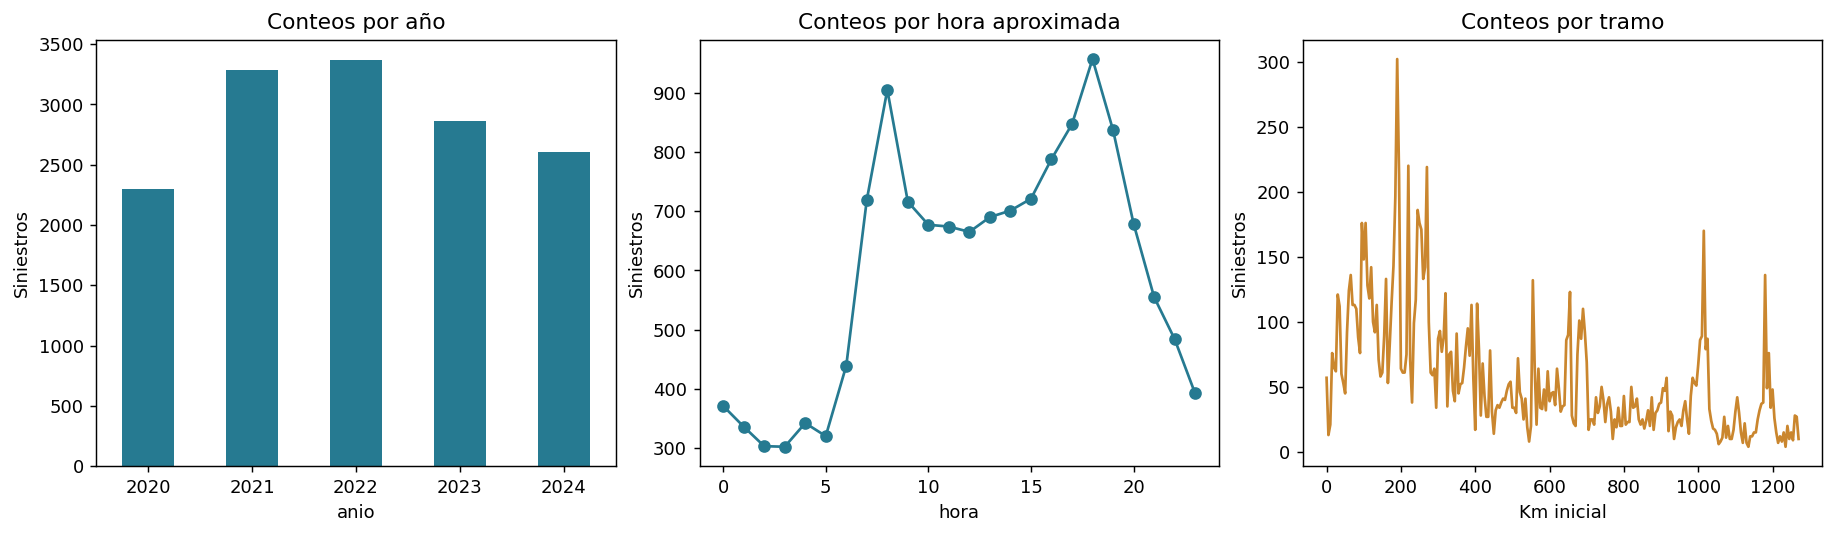

El 99.87% de las celdas civiles existentes no tiene siniestros.
Horas civiles inexistentes/repetidas: 5 5


In [5]:
anuales=eventos.groupby("anio").size().rename("Siniestros")
display(anuales.to_frame())
fig,ax=plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
anuales.plot.bar(ax=ax[0],rot=0,color="#267a91")
eventos.groupby("hora").size().reindex(range(24),fill_value=0).plot(ax=ax[1],marker="o",color="#267a91")
eventos.groupby("tramo").size().reindex(referencia.tramo,fill_value=0).plot(ax=ax[2],color="#ca862e")
for a,t in zip(ax,["Conteos por año","Conteos por hora aproximada","Conteos por tramo"]):
    a.set_title(t);a.set_ylabel("Siniestros")
ax[2].set_xlabel("Km inicial");mostrar(fig)
print(f"El {(y_base[:,expo>0]==0).mean():.2%} de las celdas civiles existentes no tiene siniestros.")
print("Horas civiles inexistentes/repetidas:",int((expo==0).sum()),int((expo==2).sum()))

La gran proporción de ceros vuelve poco informativa una accuracy aislada: predecir
siempre ausencia de siniestro ya acierta en casi todas las celdas. Para el objetivo
principal necesitamos evaluar tanto el orden de priorización como la cantidad
esperada. Más adelante cuantificamos esa comparación con las mismas observaciones.

## 5. Clima, calendario y exposición horaria

ERA5 describe las condiciones históricas de precipitación en celdas de 0,25°.
Las categorías son seco (<0,1), llovizna (0,1 ≤ p < 0,5) y lluvia (p ≥0,5 mm/h).
No confundimos este reanálisis con un pronóstico emitido antes de decidir.

La exposición del modelo representa horas reales: 0, 1 o 2 según el cambio de
horario. No es exposición vehicular. CONASET no diferencia las dos ocurrencias
de una hora repetida, por lo que se usa una aproximación explícita de conteo conjunto
y precipitación media. Los NaN de horas inexistentes no se toman como observaciones secas.

In [6]:
from datos_modelado import preparar_experimento, agrupar_modelado, atributos, expandir_prediccion
from clima_utc import cargar_cache
from integrar_flujo import serie_flujo, limites_documentados
import joblib

datos=preparar_experimento()
clima=cargar_cache()
assert np.array_equal(datos["y"],y_base)
p=clima["precip"][:,clima["exposicion_tiempo"]>0]
assert np.isfinite(p).all() and (p>=0).all()
display(pd.Series({"Celdas ERA5":len(clima["celdas"]),"Tramos":len(datos["tramos"]),
    "Etiquetas civiles":len(datos["tiempo"]),"Precipitación máxima mm/h":float(p.max()),
    "Fracción de mediciones de celda con 0 mm":float((p==0).mean())},name="Diagnóstico").to_frame())
calendario=json.loads((RAIZ/"data/calendario/feriados.json").read_text())
display(pd.Series({"Fechas marcadas en el calendario":len(calendario),
    "Primera fecha":min(calendario),"Última fecha":max(calendario)},name="Calendario histórico").to_frame())

,Diagnóstico
Celdas ERA5,59.000000
Tramos,255.000000
Etiquetas civiles,43848.000000
Precipitación máxima mm/h,11.200000
Fracción de mediciones de celda con 0 mm,0.808781


,Calendario histórico
Fechas marcadas en el calendario,243
Primera fecha,2019-12-31
Última fecha,2024-12-25


Varios tramos comparten una celda meteorológica; repetir su dato no genera
observaciones independientes. La codificación del calendario distingue inicio,
día intermedio y final de período festivo. Su cobertura es histórica y no se
extrapola automáticamente a otros años.

## 6. Incorporación del flujo vehicular

El profesor observó que un tramo puede tener más siniestros porque circulan más
vehículos. Investigamos esa limitación e incorporamos un proxy de la DGC:
**promedio mensual de pasadas por punto × 3 / días del trimestre**. Se añaden su
logaritmo y el logaritmo de los puntos implícitos, rezagados dos trimestres.

Se usan seis contratos y siete intervalos interiores conservadores. El proxy
se aplica por contrato y trimestre; no mide vehículos únicos ni el flujo horario
real de cada tramo. La cercanía a una concesión no acredita homogeneidad de tráfico.

In [7]:
flujo=pd.read_csv(SALIDA/"flujo_rezagado.csv")
cobertura=pd.read_csv(SALIDA/"cobertura_flujo.csv")
display(cobertura)
display(limites_documentados()[["contrato","km_inicio","km_fin","margen_km"]])
assert (pd.PeriodIndex(flujo.periodo_objetivo,freq="Q")-2==pd.PeriodIndex(flujo.periodo_medicion,freq="Q")).all()
assert (pd.to_datetime(flujo.fin_medicion)<pd.to_datetime(flujo.inicio_objetivo)).all()
assert flujo.loc[~flujo.flujo_disponible,["proxy_pasadas_por_punto_dia","puntos_implicitos"]].isna().all().all()
print("Tramos cubiertos:",int(datos["cubiertos"].sum()),"de",len(referencia))
print("Filas con/sin flujo:",int(flujo.flujo_disponible.sum()),int((~flujo.flujo_disponible).sum()))

,anio,tramos_con_flujo,tramos_total,siniestros_con_flujo,siniestros_total,porcentaje_eventos
0,2020,153,255,1149,2295,50.065359
1,2021,153,255,1669,3288,50.760341
2,2022,153,255,1872,3369,55.565450
3,2023,153,255,1577,2863,55.082082
4,2024,153,255,1491,2605,57.236084


,contrato,km_inicio,km_fin,margen_km
0,Talca-Chillán,219.490,412.800,1.0
1,Chillán-Collipulli,412.800,570.000,1.0
2,Collipulli-Temuco,580.000,659.520,1.0
3,Collipulli-Temuco,680.840,718.335,1.0
4,Temuco-Río Bueno,718.335,890.000,1.0
5,Río Bueno-Puerto Montt,895.450,1020.637,1.0
6,Puerto Montt-Pargua,1023.573,1079.027,1.0


Tramos cubiertos: 153 de 255
Filas con/sin flujo: 3060 2040


El rezago mantiene separados los períodos medidos y predichos, pero no acredita
que cada anexo estuviera publicado en la fecha de decisión. Los resultados con
flujo son, por tanto, retrospectivos. Los 102 tramos sin serie completa no se
rellenan con cero; los híbridos utilizan un respaldo sin flujo.

También revisamos el TMDA del PNCV: faltan mediciones de 2020, existen ceros sin
interpretar y no se acreditó la correspondencia entre ramas y tramos. Se conserva
como diagnóstico de fuente y no se convierte en denominador vehículo-km.

In [8]:
display(pd.read_csv(RAIZ/"resultados/eda/mop_capas_y_anios.csv")[["capa","titulo","anios_observados","tmda_cero","tmda_faltante"]])
display(pd.read_csv(RAIZ/"resultados/eda/mop_cruce_rol_tmda.csv"))
print("Estas tablas describen la auditoría de la fuente PNCV; no son resultados de los modelos recién entrenados.")

,capa,titulo,anios_observados,tmda_cero,tmda_faltante
0,0,2024 Sur - 2025 Norte,"2024,2025",1088,0
1,1,2022 Sur - 2023 Norte,"2022,2023",1145,0
2,2,2020 Sur - 2021 Norte,"2021,2022",1095,0
3,3,2018 Sur - 2019 Norte,"2018,2019",1096,1
4,4,2016 Sur - 2017 Norte,"2016,2017",1179,0
5,5,2014 Sur - 2015 Norte,"2014,2015",0,15


,tipo_rol,estado_tmda,filas
0,identificado,cero,63
1,identificado,faltante,15
2,identificado,positivo,12412
3,marcador,cero,5538
4,marcador,faltante,1
5,marcador,positivo,1
6,sin_rol_identificado,cero,2
7,sin_rol_identificado,positivo,257


Estas tablas describen la auditoría de la fuente PNCV; no son resultados de los modelos recién entrenados.


## 7. Cómo se ajustan los modelos y se elige la solución

En Poisson modelamos $Y_{s,t}\sim Poisson(e_t\lambda_{s,t})$. El logaritmo de la tasa
incluye efectos aditivos de tramo, hora, día de semana, mes, posición festiva,
lluvia y tendencia anual. La penalización L2 reduce la inestabilidad de los
coeficientes. GB y RF permiten relaciones más flexibles; se ajustan con pérdida o
criterio Poisson y peso de exposición, usando las mismas particiones.

Las configuraciones de búsqueda son pequeñas y se mantienen como en el protocolo
del proyecto. No ampliamos la grilla para mejorar retrospectivamente 2024. El RF
usa 80 árboles y hasta 80.000 filas agrupadas por árbol; sus hojas operan sobre
combinaciones de atributos, no sobre cada hora individual.

In [9]:
from modelos_conteo import GRILLAS
from IPython.display import Code
import inspect
from modelos_conteo import ModeloConteo

display(pd.DataFrame([{"Familia":f,"Configuración":i,"Parámetros":str(p)}
    for f,lista in GRILLAS.items() for i,p in enumerate(lista)]))
display(seleccion[(seleccion.cohorte=="ruta_completa")][["anio_prueba","familia","configuracion","anios_usados_para_elegir","parametros"]])
# Implementación utilizada por el entrenamiento que acaba de ejecutarse.
display(Code(inspect.getsource(ModeloConteo.fit),language="python"))

,Familia,Configuración,Parámetros
0,Poisson,0,{'l2': 3.0}
1,Poisson,1,{'l2': 0.3}
2,GradientBoosting,0,"{'max_leaf_nodes': 7, 'max_iter': 160}"
3,GradientBoosting,1,"{'max_leaf_nodes': 31, 'max_iter': 240}"
4,RandomForest,0,"{'max_depth': 12, 'min_samples_leaf': 100}"
5,RandomForest,1,"{'max_depth': 18, 'min_samples_leaf': 30}"


,anio_prueba,familia,configuracion,anios_usados_para_elegir,parametros
0,2022,Poisson,0,ninguno; configuración simple prefijada,"{""l2"": 3.0}"
1,2022,GradientBoosting,0,ninguno; configuración simple prefijada,"{""max_leaf_nodes"": 7, ""max_iter"": 160}"
2,2022,RandomForest,0,ninguno; configuración simple prefijada,"{""max_depth"": 12, ""min_samples_leaf"": 100}"
12,2023,Poisson,0,2022,"{""l2"": 3.0}"
13,2023,GradientBoosting,0,2022,"{""max_leaf_nodes"": 7, ""max_iter"": 160}"
14,2023,RandomForest,0,2022,"{""max_depth"": 12, ""min_samples_leaf"": 100}"
24,2024,Poisson,1,"2022,2023","{""l2"": 0.3}"
25,2024,GradientBoosting,0,"2022,2023","{""max_leaf_nodes"": 7, ""max_iter"": 160}"
26,2024,RandomForest,1,"2022,2023","{""max_depth"": 18, ""min_samples_leaf"": 30}"


def fit(self, f, y, expo):
        t0 = time.monotonic()
        x = self._entrada(f)
        y, expo = np.asarray(y, float), np.asarray(expo, float)
        if len(x) != len(y) or y.shape != expo.shape or (y < 0).any() or (expo <= 0).any():
            raise ValueError("Datos/exposición inválidos")
        if self.familia == "GradientBoosting":
            categoricas = [c < 6 for c in self.columnas]
            self.modelo = HistGradientBoostingRegressor(loss="poisson", categorical_features=categoricas,
                            learning_rate=.05, min_samples_leaf=100, l2_regularization=1,
                            early_stopping=False, random_state=self.semilla, **self.parametros)
            self.modelo.fit(x, y / expo, sample_weight=expo)
            self.diagnostico = {"iteraciones": self.modelo.n_iter_, "early_stopping": False}
        else:
            cats = [i for i, c in enumerate(self.columnas) if c < 6]
            nums = [i for i, c in enumerate(self.columnas) if c >= 6]
            partes = [("categorias", OneHotEncoder(handle_unknown="ignore", dtype=np.float32), cats)]
            if nums:
                partes.append(("numericas", StandardScaler(), nums))
            self.transformador = ColumnTransformer(partes, sparse_threshold=1.0)
            xx = sparse.csr_matrix(self.transformador.fit_transform(x))
            if self.familia == "Poisson":
                xx = sparse.hstack([xx, np.ones((len(y), 1))]).tocsr()
                self.coef, self.diagnostico = ajustar(xx, y, expo, l2=self.parametros["l2"], devolver_diagnostico=True)
            elif self.familia == "RandomForest":
                self.modelo = RandomForestRegressor(n_estimators=80, criterion="poisson", bootstrap=True,
                                max_samples=min(80000, len(y)), max_features=.8, n_jobs=2,
                                random_state=self.semilla, **self.parametros)
                self.modelo.fit(xx, y / expo, sample_weight=expo)
                self.diagnostico = {"arboles": len(self.modelo.estimators_), "muestra_por_arbol": min(80000, len(y)),
                                    "criterio": "poisson", "hojas_sobre_filas_agrupadas": True}
            else:
                raise ValueError("Familia desconocida")
        self.diagnostico["segundos_ajuste"] = time.monotonic() - t0
        return self

La separación temporal busca medir generalización a un año posterior. Los resultados
de 2022/2023 sirven para elegir; 2024 se reserva de esa selección, aunque su
inspección previa obliga a llamarlo evaluación histórica reutilizada. Las
transformaciones de atributos se ajustan con entrenamiento. La tabla siguiente
reproduce la elección usando únicamente los resultados de esta corrida.

In [10]:
cv=metricas[(metricas.particion=="prueba")&(metricas.anio_prueba<2024)&
    metricas.cohorte.isin(["ruta_completa","hibrido_ruta_completa"])&(metricas.modelo!="M0")]
medias=cv.groupby("modelo").captura5.mean()
preferencia=["M1"]+[f"{f}_clima" for f in GRILLAS]+[f"Hibrido_{f}_{v}" for v in ["clima","clima_flujo"] for f in GRILLAS]
candidata=next(n for n in preferencia if medias[n]>=medias.max()-.001)
assert candidata==auditoria["modelo_candidato_por_cv_pre2024"]
display(pd.DataFrame({"Captura media 2022/2023 (%)":medias*100,
    "Distancia al mejor (pp)":(medias.max()-medias)*100,
    "Dentro de tolerancia":medias>=medias.max()-.001}).sort_values("Captura media 2022/2023 (%)",ascending=False).round(4))
display(Markdown(f"La regla temporal selecciona **{candidata}**. Su captura media anterior a 2024 es **{medias[candidata]*100:.3f} %**, "
    f"frente a **{medias.max()*100:.3f} %** del mejor promedio. La distancia es **{(medias.max()-medias[candidata])*100:.3f} puntos porcentuales**."))

,Captura media 2022/2023 (%),Distancia al mejor (pp),Dentro de tolerancia
modelo,,,
GradientBoosting_clima,19.1142,0.0000,True
Poisson_clima,19.0888,0.0254,True
Hibrido_Poisson_clima,19.0765,0.0377,True
Hibrido_GradientBoosting_clima_flujo,18.8487,0.2655,False
Hibrido_GradientBoosting_clima,18.8129,0.3013,False
Hibrido_Poisson_clima_flujo,18.7762,0.3380,False
Hibrido_RandomForest_clima_flujo,15.9037,3.2105,False
Hibrido_RandomForest_clima,15.7884,3.3258,False
RandomForest_clima,15.4436,3.6706,False


La regla temporal selecciona **Poisson_clima**. Su captura media anterior a 2024 es **19.089 %**, frente a **19.114 %** del mejor promedio. La distancia es **0.025 puntos porcentuales**.

## 8. Qué métricas responden a cada pregunta

Como la respuesta es un conteo, evaluamos tanto la cantidad esperada como la
priorización de tramos. Complementamos ese análisis con un diagnóstico de celdas
con o sin siniestros, que permite interpretar accuracy, F1 y las curvas ROC/PR.
Cada grupo de métricas responde a una pregunta distinta:

| Pregunta | Métricas | Unidad y alcance |
|---|---|---|
| ¿Dónde priorizar con un presupuesto limitado? | Captura 5/10/20 % e IC por bloques | Fracción de siniestros históricos concentrados; no accidentes evitados |
| ¿Qué ocurre si los tramos permanecen fijos? | Captura por turno de 12 h | Misma ubicación durante el turno; presupuesto fraccionario al 5 % |
| ¿Cuántos siniestros esperar? | MAE, RMSE, desvianza de Poisson y O/E | Conteos por celda o total de la cohorte por turno, identificados por separado |
| ¿Cómo se separan celdas con/sin evento? | Accuracy, precision, recall, F1, balanced accuracy, ROC-AUC, PR-AUC/AP y matriz de confusión | Diagnóstico binario auxiliar con etiqueta `conteo > 0` |

La captura global permite cambiar de tramo cada hora; por turno los tramos se
mantienen fijos. MAE y RMSE del total por turno no son errores por tramo. O/E menor
que 1 indica sobreestimación agregada, y mayor que 1, subestimación. La desvianza
compara conteos dentro de la misma población. El R² se muestra como diagnóstico
adicional del error frente a una media, sin utilizarlo para seleccionar el modelo.
MAE resume el error absoluto medio; RMSE penaliza con mayor fuerza los errores
grandes. Un R² negativo indica que, para ese error cuadrático y esa agregación,
la predicción es peor que utilizar la media observada de referencia; no equivale
por sí solo a una evaluación del ranking de vigilancia.
No usamos MAPE porque la gran cantidad de ceros vuelve problemática su interpretación.

## 9. Comparación de modelos en la ruta completa

La siguiente tabla utiliza exclusivamente prueba 2024 y los mismos 255 tramos.
Las métricas fueron calculadas al predecir con los modelos entrenados hasta 2023.
Mostramos las referencias junto con las tres familias para separar cuánto aporta
el mapa espacial de lo que agrega el contexto dinámico.

In [11]:
prueba=metricas[(metricas.particion=="prueba")&(metricas.cohorte=="ruta_completa")]
tabla2024=prueba[prueba.anio_prueba==2024].copy()
extras2024=conteo_extra[(conteo_extra.anio_prueba==2024)&(conteo_extra.cohorte=="ruta_completa")&(conteo_extra.particion=="prueba")]
comparacion=tabla2024.merge(extras2024,on=["anio_prueba","cohorte","modelo","particion"],validate="one_to_one")
comparacion["captura5_pct"]=comparacion.captura5*100
comparacion["captura10_pct"]=comparacion.captura10*100
comparacion["captura20_pct"]=comparacion.captura20*100
comparacion["captura_turno_pct"]=comparacion.captura5_turno*100
muestra2024=y_base[:,tiempo.year==2024]
valida2024=expo[tiempo.year==2024]>0
var_celda=muestra2024[:,valida2024].var()
var_turno=muestra2024.reshape(len(referencia),-1,12).sum(axis=(0,2)).var()
comparacion["r2_celda"]=1-comparacion.rmse_celda**2/var_celda
comparacion["r2_total_turno"]=1-comparacion.rmse_total_turno**2/var_turno
display(Markdown("**Priorización: captura de siniestros con el mismo presupuesto.**"))
display(comparacion[["modelo","captura5_pct","captura10_pct","captura20_pct","captura_turno_pct"]].round(4))
display(Markdown("**Conteos: calibración y error en la misma población de prueba.**"))
display(comparacion[["modelo","observado_esperado","mae_celda","rmse_celda","mae_12h_calendario","rmse_total_turno","r2_total_turno","desvianza_por_hora"]].round(5))
cohorte_candidata="hibrido_ruta_completa" if candidata.startswith("Hibrido_") else "ruta_completa"
c2024=metricas[(metricas.anio_prueba==2024)&(metricas.particion=="prueba")&
    (metricas.cohorte==cohorte_candidata)&(metricas.modelo==candidata)].iloc[0]
base2024=tabla2024[tabla2024.modelo=="M1"].iloc[0]
display(Markdown(f"En esta ejecución, **{candidata}** captura **{c2024.captura5:.2%}** de los eventos con el 5 % del presupuesto global, "
    f"frente a **{base2024.captura5:.2%}** de M1. Con tramos fijos por turno, su captura es **{c2024.captura5_turno:.2%}**. "
    f"El MAE del total por turno es **{c2024.mae_12h_calendario:.3f}** siniestros y O/E es **{c2024.observado_esperado:.3f}**. "
    "Estas cifras permiten evaluar por separado priorización y cantidad."))

**Priorización: captura de siniestros con el mismo presupuesto.**

,modelo,captura5_pct,captura10_pct,captura20_pct,captura_turno_pct
0,M1,14.8944,26.4683,43.6340,14.8944
1,M0,5.0000,10.0000,20.0000,5.0000
2,Poisson_clima,19.0019,30.4319,47.2169,15.8445
3,GradientBoosting_clima,20.0000,31.3244,48.1766,17.2649
4,RandomForest_clima,16.1228,26.7946,43.8388,15.7774


**Conteos: calibración y error en la misma población de prueba.**

,modelo,observado_esperado,mae_celda,rmse_celda,mae_12h_calendario,rmse_total_turno,r2_total_turno,desvianza_por_hora
0,M1,0.88012,0.00248,0.03470,1.86130,2.36570,-0.04334,0.01526
1,M0,0.88012,0.00248,0.03471,1.86130,2.36570,-0.04334,0.01579
2,Poisson_clima,0.77202,0.00266,0.03470,1.97033,2.46128,-0.12935,0.01516
3,GradientBoosting_clima,0.87414,0.00249,0.03469,1.75178,2.24259,0.06242,0.01507
4,RandomForest_clima,0.82931,0.00256,0.03470,1.86151,2.33267,-0.01442,0.01537


En esta ejecución, **Poisson_clima** captura **19.00%** de los eventos con el 5 % del presupuesto global, frente a **14.89%** de M1. Con tramos fijos por turno, su captura es **15.84%**. El MAE del total por turno es **1.970** siniestros y O/E es **0.772**. Estas cifras permiten evaluar por separado priorización y cantidad.

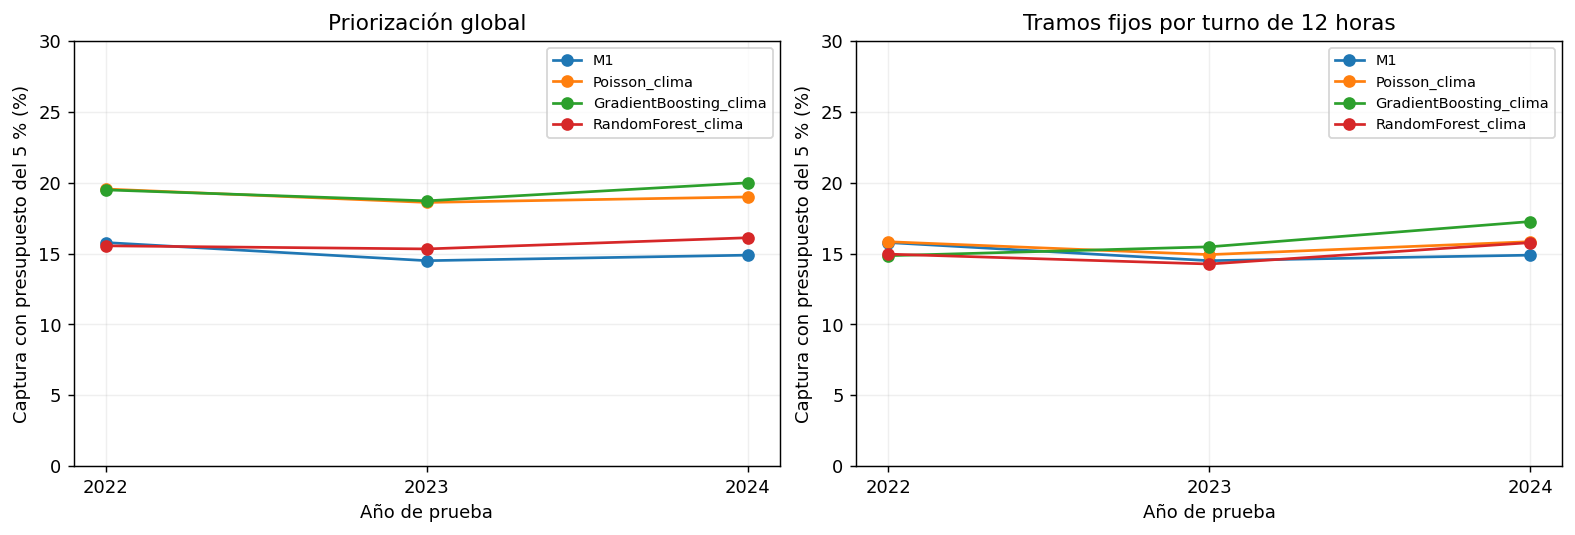

In [12]:
fig,ax=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for nombre in ["M1","Poisson_clima","GradientBoosting_clima","RandomForest_clima"]:
    d=prueba[prueba.modelo==nombre].sort_values("anio_prueba")
    ax[0].plot(d.anio_prueba,d.captura5*100,"o-",label=nombre)
    ax[1].plot(d.anio_prueba,d.captura5_turno*100,"o-",label=nombre)
for a,t in zip(ax,["Priorización global","Tramos fijos por turno de 12 horas"]):
    a.set(title=t,xlabel="Año de prueba",ylabel="Captura con presupuesto del 5 % (%)",xticks=[2022,2023,2024],ylim=(0,30))
    a.grid(alpha=.2);a.legend(fontsize=8)
mostrar(fig)

Una captura favorable no resuelve automáticamente la calibración. Además, un modelo
puede ganar en 2024 y no ser el seleccionado, porque la decisión se tomó con los
años anteriores. La comparación debe conservar ambos resultados en lugar de cambiar
la regla después de mirar la prueba.

## 10. Validación temporal e incertidumbre

Comparamos entrenamiento y prueba con la misma métrica. Una brecha grande puede
reflejar sobreajuste y cambios temporales; por sí sola no identifica la causa.
Los intervalos siguientes usan 2.000 remuestreos semanales pareados, manteniendo
predicciones y selección fijas. No incorporan incertidumbre del reentrenamiento ni
corrigen múltiples comparaciones.

In [13]:
brecha=metricas[(metricas.cohorte=="ruta_completa")&metricas.modelo.isin(["Poisson_clima","GradientBoosting_clima","RandomForest_clima"])].pivot(index=["anio_prueba","modelo"],columns="particion",values="captura5").reset_index()
brecha["brecha_pp"]=(brecha["train"]-brecha["prueba"])*100
display(brecha.round(5))
ventaja=bootstrap[(bootstrap.cohorte==cohorte_candidata)&(bootstrap.modelo==candidata)&(bootstrap.referencia=="M1")]
display(ventaja[["anio_prueba","diferencia_pp","ic95_inf_pp","ic95_sup_pp","replicas_validas"]].round(4))
intervalo2024=ventaja[ventaja.anio_prueba==2024].iloc[0]
display(Markdown(f"La diferencia de captura de la candidata frente a M1 en 2024 es **{intervalo2024.diferencia_pp:.2f} pp**, "
    f"con IC95 % **[{intervalo2024.ic95_inf_pp:.2f}; {intervalo2024.ic95_sup_pp:.2f}] pp**. "
    "Un intervalo que incluya cero se debe comunicar como evidencia insuficiente para distinguir la mejora en ese año, no como igualdad demostrada."))

particion,anio_prueba,modelo,prueba,train,brecha_pp
0,2022,GradientBoosting_clima,0.19501,0.31327,11.82591
1,2022,Poisson_clima,0.19561,0.24575,5.01390
2,2022,RandomForest_clima,0.15554,0.21171,5.61784
3,2023,GradientBoosting_clima,0.18727,0.27636,8.90920
4,2023,Poisson_clima,0.18617,0.22676,4.05966
5,2023,RandomForest_clima,0.15334,0.19672,4.33802
6,2024,GradientBoosting_clima,0.20000,0.26009,6.00931
7,2024,Poisson_clima,0.19002,0.21718,2.71624
8,2024,RandomForest_clima,0.16123,0.20245,4.12261


,anio_prueba,diferencia_pp,ic95_inf_pp,ic95_sup_pp,replicas_validas
0,2022,3.7771,1.4115,6.0931,2000
27,2023,4.1128,1.9699,6.1197,2000
54,2024,4.1075,2.0987,6.0803,2000


La diferencia de captura de la candidata frente a M1 en 2024 es **4.11 pp**, con IC95 % **[2.10; 6.08] pp**. Un intervalo que incluya cero se debe comunicar como evidencia insuficiente para distinguir la mejora en ese año, no como igualdad demostrada.

## 11. Cuánto aportan la lluvia y el proxy de circulación

La lluvia se compara como clima menos calendario, y el flujo como clima+flujo menos
clima. Son contrastes distintos sobre los mismos 153 tramos, con idénticos eventos
y presupuesto. El híbrido de toda la ruta se informa aparte, porque también cambia
la escala relativa entre el especialista y el respaldo.

,aporte,anio_prueba,modelo,referencia,diferencia_pp,ic95_inf_pp,ic95_sup_pp
0,lluvia,2022,Poisson_clima,Poisson_calendario,0.8547,-0.8066,2.6224
1,lluvia,2022,GradientBoosting_clima,GradientBoosting_calendario,1.4423,-0.1689,3.0192
2,lluvia,2022,RandomForest_clima,RandomForest_calendario,-0.1603,-2.2094,1.9213
3,lluvia,2023,Poisson_clima,Poisson_calendario,1.5219,-0.3882,3.4978
4,lluvia,2023,GradientBoosting_clima,GradientBoosting_calendario,3.3608,1.3517,5.5204
5,lluvia,2023,RandomForest_clima,RandomForest_calendario,0.4439,-1.9785,2.9525
6,lluvia,2024,Poisson_clima,Poisson_calendario,1.1402,-1.2399,3.5410
7,lluvia,2024,GradientBoosting_clima,GradientBoosting_calendario,2.3474,-0.1321,4.9203
8,lluvia,2024,RandomForest_clima,RandomForest_calendario,0.5366,-2.2229,3.6488
9,flujo,2022,Poisson_clima_flujo,Poisson_clima,-0.3205,-1.0051,0.3093


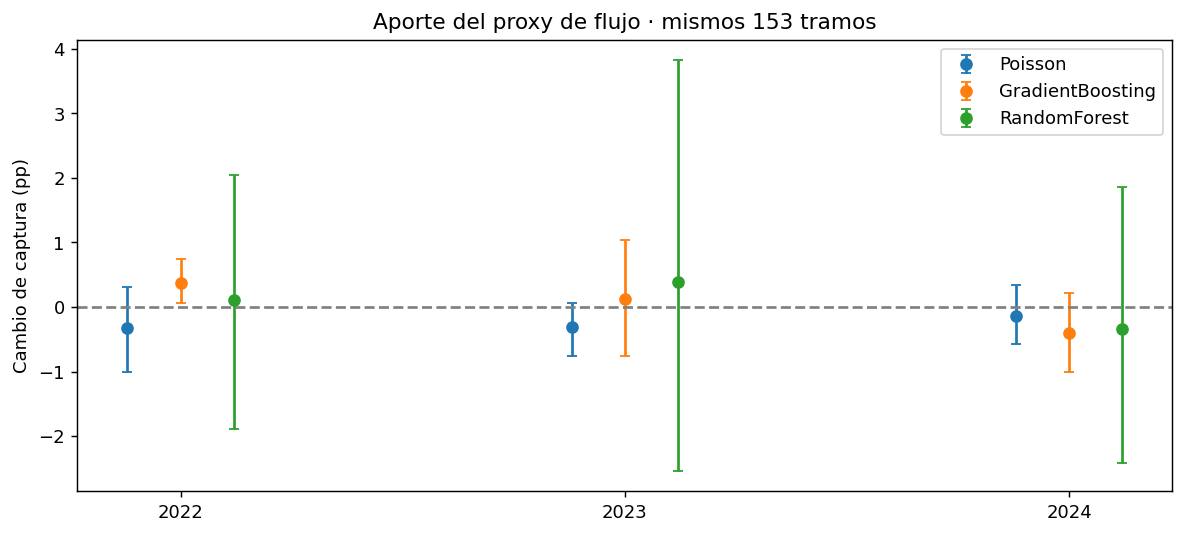

De los **9** contrastes de flujo, **1** tienen un intervalo completamente positivo. La utilidad se juzga por consistencia entre años, signo y magnitud. Un resultado débil de este proxy agregado no prueba que el tráfico real no importe.

In [14]:
aportes=bootstrap[(bootstrap.cohorte=="con_contrato")&
    (bootstrap.referencia==bootstrap.modelo.str.replace("_clima_flujo","_clima",regex=False))].copy()
lluvia=bootstrap[(bootstrap.cohorte=="con_contrato")&bootstrap.modelo.str.endswith("_clima")&
    (bootstrap.referencia==bootstrap.modelo.str.replace("_clima","_calendario",regex=False))].copy()
aportes["aporte"]="flujo";lluvia["aporte"]="lluvia"
aportes=pd.concat([lluvia,aportes],ignore_index=True)
display(aportes[["aporte","anio_prueba","modelo","referencia","diferencia_pp","ic95_inf_pp","ic95_sup_pp"]].round(4))
fig,ax=plt.subplots(figsize=(9,4),constrained_layout=True)
for i,fam in enumerate(GRILLAS):
    d=aportes[(aportes.aporte=="flujo")&(aportes.modelo==fam+"_clima_flujo")].sort_values("anio_prueba")
    ax.errorbar(d.anio_prueba+(i-1)*.12,d.diferencia_pp,
        yerr=np.maximum(0,np.array([d.diferencia_pp-d.ic95_inf_pp,d.ic95_sup_pp-d.diferencia_pp])),fmt="o",capsize=3,label=fam)
ax.axhline(0,color="gray",ls="--");ax.set(xticks=[2022,2023,2024],ylabel="Cambio de captura (pp)",title="Aporte del proxy de flujo · mismos 153 tramos")
ax.legend();mostrar(fig)
flujo_pos=aportes[(aportes.aporte=="flujo")&(aportes.ic95_inf_pp>0)]
display(Markdown(f"De los **{sum(aportes.aporte=='flujo')}** contrastes de flujo, **{len(flujo_pos)}** tienen un intervalo completamente positivo. "
    "La utilidad se juzga por consistencia entre años, signo y magnitud. Un resultado débil de este proxy agregado no prueba que el tráfico real no importe."))

## 12. Evaluación binaria auxiliar: accuracy, F1, ROC y precisión–recall

Para responder también la pregunta “¿hubo al menos un siniestro?”, definimos la
etiqueta binaria como `y > 0` en cada celda civil existente. El score es el conteo
esperado por el modelo. Esto evalúa discriminación sobre otra representación de la
respuesta; no transforma la regresión entrenada en un clasificador ni sustituye
las métricas principales.

El umbral se fija como el percentil 95 de las predicciones de **entrenamiento**, con
regla estricta `score > umbral`. No se optimiza F1 ni se usa el año de prueba para
escogerlo. El porcentaje alertado en prueba puede diferir de 5 % por los empates y
los cambios entre años. Los híbridos no tienen una partición train en este protocolo,
por lo que no se inventa un umbral para ellos.

- **Accuracy:** fracción de celdas correctamente clasificadas; puede ser alta por los ceros.
- **Precision:** fracción de alertas que coincide con una celda positiva.
- **Recall:** fracción de celdas positivas detectadas; no es exactamente captura de conteos cuando hay varios eventos en una celda.
- **F1:** media armónica de precision y recall para este umbral concreto.
- **ROC-AUC:** capacidad de ordenar positivos frente a negativos a través de umbrales.
- **PR-AUC/AP:** average precision, resumen de precisión–recall especialmente útil ante positivos raros; se compara con la prevalencia.

También mostramos balanced accuracy y especificidad. Si no hay predicciones
positivas, precision y F1 se informan como cero por convención explícita. ROC-AUC
queda indefinida si solo existe una clase. Las áreas se calcularon con todos los
scores, aunque las curvas se dibujan con un subconjunto de puntos para aligerar el archivo.
Average precision no es el área trapezoidal por interpolación lineal; se identifica
como AP para mantener explícita esa definición.

In [15]:
b2024=binarias[(binarias.anio_prueba==2024)&(binarias.cohorte=="ruta_completa")].copy()
columnas_bin=["modelo","prevalencia","umbral_train_p95","fraccion_alertada","accuracy","precision","recall","f1","balanced_accuracy","roc_auc","pr_auc_ap"]
display(b2024[columnas_bin].round(6))
display(Markdown("**Generalización temporal del diagnóstico auxiliar: tres años de prueba.**"))
display(binarias[(binarias.cohorte=="ruta_completa")&binarias.modelo.isin(
    ["Poisson_clima","GradientBoosting_clima","RandomForest_clima"])][
    ["anio_prueba","modelo","accuracy","precision","recall","f1","roc_auc","pr_auc_ap"]].round(6))
nombre_aux=candidata if candidata in set(b2024.modelo) else "Poisson_clima"
bc=b2024[b2024.modelo==nombre_aux].iloc[0]
matriz=pd.DataFrame([[int(bc.tn),int(bc.fp)],[int(bc.fn),int(bc.tp)]],
    index=["Real: ningún siniestro","Real: al menos uno"],columns=["Predicho: ningún siniestro","Predicho: al menos uno"])
display(Markdown(f"**Matriz de confusión: {nombre_aux}, prueba 2024.**"));display(matriz)
display(Markdown(f"La prevalencia observada es **{bc.prevalencia:.3%}**. Predecir siempre cero obtiene accuracy **{bc.accuracy_siempre_cero:.3%}**, "
    "pero recall y F1 iguales a cero. "
    f"Para **{nombre_aux}**, con el umbral fijado en entrenamiento, accuracy es **{bc.accuracy:.3%}**, precision **{bc.precision:.3%}**, "
    f"recall **{bc.recall:.3%}** y F1 **{bc.f1:.4f}**. ROC-AUC es **{bc.roc_auc:.4f}** y average precision **{bc.pr_auc_ap:.5f}**. "
    "La accuracy aislada favorecería una solución que no identifica eventos; por eso no se utiliza para seleccionar el modelo de conteos."))

,modelo,prevalencia,umbral_train_p95,fraccion_alertada,accuracy,precision,recall,f1,balanced_accuracy,roc_auc,pr_auc_ap
32,M1,0.001142,0.003466,0.047082,0.952109,0.003537,0.145817,0.006907,0.549424,0.689010,0.002514
33,M0,0.001142,0.001321,0.000114,0.998745,0.003922,0.000391,0.000711,0.500139,0.500139,0.001143
34,Poisson_clima,0.001142,0.003919,0.069143,0.930258,0.003933,0.238077,0.007737,0.584563,0.710303,0.003642
35,GradientBoosting_clima,0.001142,0.003950,0.047468,0.951825,0.004590,0.190774,0.008965,0.571735,0.712327,0.003577
36,RandomForest_clima,0.001142,0.002503,0.061401,0.937873,0.003389,0.182174,0.006654,0.560455,0.678426,0.002687


**Generalización temporal del diagnóstico auxiliar: tres años de prueba.**

,anio_prueba,modelo,accuracy,precision,recall,f1,roc_auc,pr_auc_ap
2,2022,Poisson_clima,0.841094,0.003824,0.410109,0.007578,0.707587,0.004279
3,2022,GradientBoosting_clima,0.929530,0.005189,0.244552,0.010163,0.701999,0.004271
4,2022,RandomForest_clima,0.924027,0.004077,0.207022,0.007997,0.670338,0.003117
18,2023,Poisson_clima,0.886399,0.003506,0.315415,0.006935,0.701497,0.003467
19,2023,GradientBoosting_clima,0.936153,0.004354,0.218583,0.008538,0.701511,0.004048
20,2023,RandomForest_clima,0.939070,0.003650,0.174439,0.007150,0.669708,0.002815
34,2024,Poisson_clima,0.930258,0.003933,0.238077,0.007737,0.710303,0.003642
35,2024,GradientBoosting_clima,0.951825,0.004590,0.190774,0.008965,0.712327,0.003577
36,2024,RandomForest_clima,0.937873,0.003389,0.182174,0.006654,0.678426,0.002687


**Matriz de confusión: Poisson_clima, prueba 2024.**

,Predicho: ningún siniestro,Predicho: al menos uno
Real: ningún siniestro,2082858,154249
Real: al menos uno,1949,609


La prevalencia observada es **0.114%**. Predecir siempre cero obtiene accuracy **99.886%**, pero recall y F1 iguales a cero. Para **Poisson_clima**, con el umbral fijado en entrenamiento, accuracy es **93.026%**, precision **0.393%**, recall **23.808%** y F1 **0.0077**. ROC-AUC es **0.7103** y average precision **0.00364**. La accuracy aislada favorecería una solución que no identifica eventos; por eso no se utiliza para seleccionar el modelo de conteos.

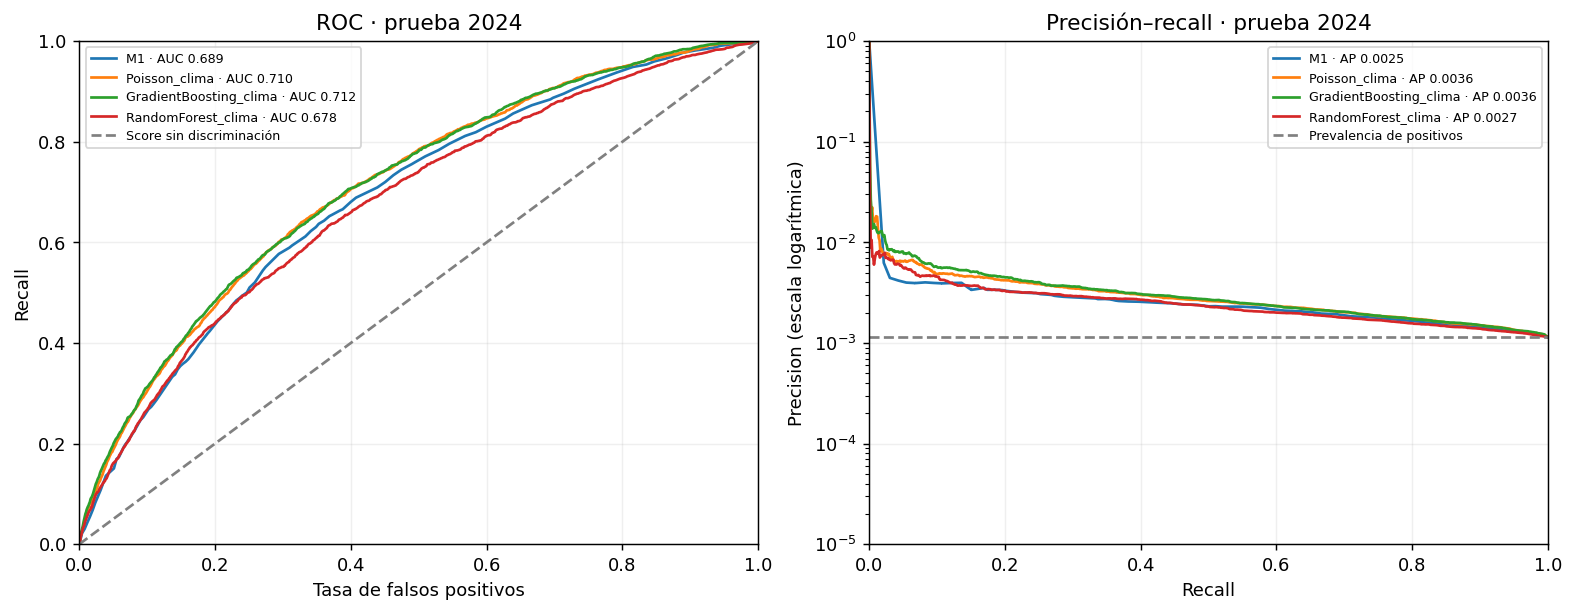

En la gráfica PR logarítmica se omiten los puntos de precisión cero; las áreas usan todos los datos.


In [16]:
fig,ax=plt.subplots(1,2,figsize=(12,4.6),constrained_layout=True)
for nombre in ["M1","Poisson_clima","GradientBoosting_clima","RandomForest_clima"]:
    bm=b2024[b2024.modelo==nombre].iloc[0]
    for j,tipo in enumerate(["ROC","PR"]):
        d=curvas_binarias[(curvas_binarias.modelo==nombre)&(curvas_binarias.curva==tipo)]
        if tipo=="ROC":ax[j].plot(d.x,d.y,label=f"{nombre} · AUC {bm.roc_auc:.3f}")
        else:
            d=d[d.y>0];ax[j].plot(d.x,d.y,label=f"{nombre} · AP {bm.pr_auc_ap:.4f}")
ax[0].plot([0,1],[0,1],"--",color="gray",label="Score sin discriminación")
ax[0].set(title="ROC · prueba 2024",xlabel="Tasa de falsos positivos",ylabel="Recall",xlim=(0,1),ylim=(0,1))
ax[1].axhline(bc.prevalencia,ls="--",color="gray",label="Prevalencia de positivos")
ax[1].set(title="Precisión–recall · prueba 2024",xlabel="Recall",ylabel="Precision (escala logarítmica)",xlim=(0,1),yscale="log",ylim=(1e-5,1))
for a in ax:a.legend(fontsize=7);a.grid(alpha=.2)
mostrar(fig)
print("En la gráfica PR logarítmica se omiten los puntos de precisión cero; las áreas usan todos los datos.")

La curva ROC puede parecer favorable aun cuando la precisión de las alertas sea
baja, porque los negativos dominan. La curva PR y la prevalencia permiten ver ese
problema. Estas métricas describen celdas con/sin evento, mientras que captura y
MAE responden a la priorización y a los conteos. Ninguna de ellas demuestra por sí
sola que el sistema permita prevenir un siniestro individual.

## 13. Calibración de conteos y efecto de la tendencia

El ranking y la escala de los conteos son problemas distintos. Evaluamos una
variante que multiplica las predicciones por el O/E fuera de muestra del año anterior.
El factor de 2023 procede de 2022, y el de 2024 de 2023. Así evitamos corregir una
predicción utilizando el resultado que intentamos predecir.

Un factor global positivo conserva el orden y la captura. Puede mejorar MAE y,
aun así, desplazar el sesgo al otro lado de O/E=1. La tendencia anual también
extrapola fuera del entrenamiento; observamos su coeficiente, sin atribuirle
causalmente toda la diferencia entre años.

,anio_prueba,ajuste,anio_factor,factor,observado_esperado,mae_12h_calendario,captura5
0,2023,original,NaN,1.00000,0.66874,2.53603,0.18617
1,2023,recalibrado,2022.0,0.69320,0.96472,1.78399,0.18617
2,2024,original,NaN,1.00000,0.77202,1.97033,0.19002
3,2024,recalibrado,2023.0,0.66874,1.15444,1.68391,0.19002


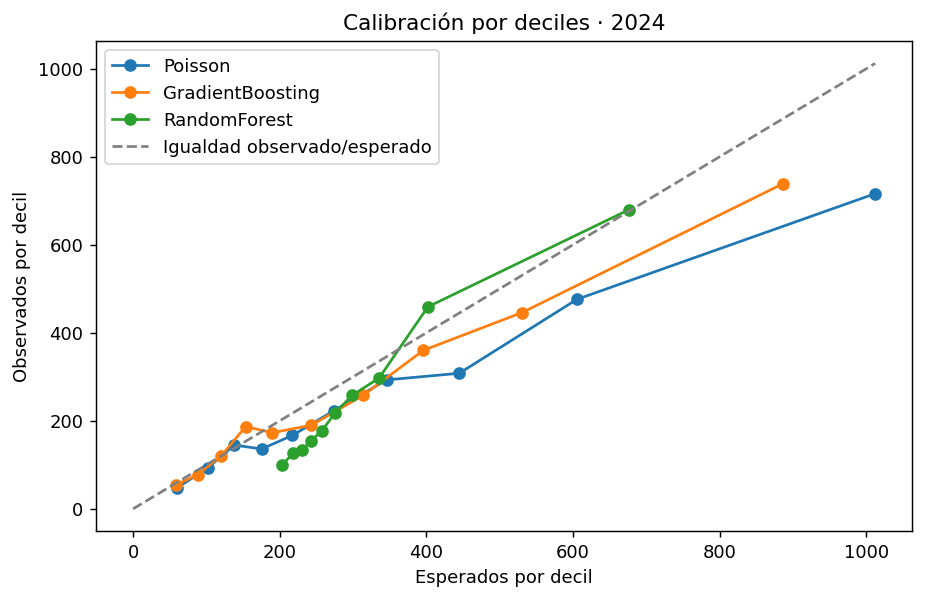

La variante recalibrada de 2024 obtiene O/E **1.154** y MAE del total por turno **1.684**. El resultado se compara con la variante original, sin elegir entre ambas mirando este año de prueba.

In [17]:
display(recalibracion[["anio_prueba","ajuste","anio_factor","factor","observado_esperado","mae_12h_calendario","captura5"]].round(5))
for anio in [2023,2024]:
    d=recalibracion[recalibracion.anio_prueba==anio].set_index("ajuste")
    assert d.loc["recalibrado","anio_factor"]==anio-1
    np.testing.assert_allclose(d.loc["original","captura5"],d.loc["recalibrado","captura5"])
cal=pd.read_csv(SALIDA/"calibracion.csv")
fig,ax=plt.subplots(figsize=(7,4.5),constrained_layout=True)
for fam in GRILLAS:
    d=cal[(cal.anio_prueba==2024)&(cal.cohorte=="ruta_completa")&(cal.modelo==fam+"_clima")]
    ax.plot(d.esperados,d.observados,"o-",label=fam)
maximo=cal[(cal.anio_prueba==2024)&(cal.cohorte=="ruta_completa")][["esperados","observados"]].to_numpy().max()
ax.plot([0,maximo],[0,maximo],"--",color="gray",label="Igualdad observado/esperado")
ax.set(xlabel="Esperados por decil",ylabel="Observados por decil",title="Calibración por deciles · 2024")
ax.legend();mostrar(fig)
rc2024=recalibracion[(recalibracion.anio_prueba==2024)&(recalibracion.ajuste=="recalibrado")].iloc[0]
display(Markdown(f"La variante recalibrada de 2024 obtiene O/E **{rc2024.observado_esperado:.3f}** y MAE del total por turno **{rc2024.mae_12h_calendario:.3f}**. "
    "El resultado se compara con la variante original, sin elegir entre ambas mirando este año de prueba."))

## 14. Interpretación del modelo y ejemplo de turno

Para interpretar Poisson comparamos combinaciones observadas de 2024 que solo
difieren en un atributo. Como el modelo es aditivo y log-lineal, una categoría
multiplica la tasa por el mismo factor en todas esas combinaciones. Son asociaciones
condicionales del modelo; no son efectos causales y no tienen intervalos de
confianza de coeficientes en esta entrega.

El artefacto evaluado en 2024 se ajustó hasta 2023. El reajustado con 2020–2024
incorpora todos los eventos y no tiene una prueba futura. Mantener esas versiones
separadas evita presentar un ajuste sobre todos los datos como validación.

In [18]:
modelo_poisson=joblib.load(SALIDA/"artefactos/ruta_completa_Poisson_clima_2024.joblib")
k24=agrupar_modelado(datos,np.arange(len(referencia)),2024)[0]
f24=atributos(k24,datos)
coefs=modelo_poisson.coef
cats=modelo_poisson.transformador.named_transformers_["categorias"].categories_
valores={};offset=0
for columna,categorias in enumerate(cats):
    valores[columna]=dict(zip(categorias,coefs[offset:offset+len(categorias)]));offset+=len(categorias)
filas_contraste=[]
for j,nombre,ref,alternativas in [(5,"Lluvia",0,[1,2]),(4,"Posición festiva",0,[1,2,3]),(1,"Hora",12,[2,8,18])]:
    for nivel in alternativas:
        filas_contraste.append({"Variable":nombre,"Referencia":ref,"Comparado":nivel,
            "Razón de tasas":float(np.exp(valores[j][nivel]-valores[j][ref]))})
display(pd.DataFrame(filas_contraste).round(4))
mu24,yy24,e24=expandir_prediccion(k24,modelo_poisson.predict_rate(f24),datos,np.arange(len(referencia)),[2024])
from evaluacion import pesos_seleccion
horas24=datos["tiempo"][datos["tiempo"].year==2024]
j=int(np.flatnonzero(horas24==pd.Timestamp("2024-07-12 12:00"))[0])
mu_turno=mu24[:,j:j+12].sum(axis=1);y_turno=yy24[:,j:j+12].sum(axis=1)
peso=pesos_seleccion(mu_turno,np.ones(len(referencia)),.05)
ejemplo=pd.DataFrame({"km_inicio":referencia.tramo,"esperados_12h":mu_turno,"observados_12h":y_turno,"peso_presupuesto":peso})
display(ejemplo[ejemplo.peso_presupuesto>0].sort_values("esperados_12h",ascending=False).round(5))
print(f"Turno ilustrativo 12/07/2024 12:00–24:00: {mu_turno.sum():.3f} esperados y {int(y_turno.sum())} observados en toda la ruta.")

,Variable,Referencia,Comparado,Razón de tasas
0,Lluvia,0,1,1.2846
1,Lluvia,0,2,2.1109
2,Posición festiva,0,1,1.1756
3,Posición festiva,0,2,0.9270
4,Posición festiva,0,3,1.1220
5,Hora,12,2,0.4364
6,Hora,12,8,1.3791
7,Hora,12,18,1.4061


,km_inicio,esperados_12h,observados_12h,peso_presupuesto
38,190,0.13508,1.0,1.00
54,270,0.10796,0.0,1.00
44,220,0.10309,0.0,1.00
39,195,0.10081,0.0,1.00
37,185,0.08979,0.0,1.00
49,245,0.08039,0.0,1.00
50,250,0.07925,0.0,1.00
21,105,0.07862,0.0,1.00
19,95,0.07640,1.0,1.00
24,120,0.06935,0.0,1.00


Turno ilustrativo 12/07/2024 12:00–24:00: 6.344 esperados y 5 observados en toda la ruta.


La lluvia de categoría 2 corresponde a ≥0,5 mm/h; la categoría 1, a 0,1–0,5 con
límite superior excluido. Las posiciones festivas 1, 2 y 3 son inicio, intermedio
y final. Una razón mayor que uno indica un conteo esperado mayor que la referencia,
no mayor riesgo por conductor. La circulación no observada puede contribuir a los
patrones horarios y festivos.

El turno anterior es ilustrativo, no una estimación de precisión basada en un caso.
Su presupuesto admite 12 tramos completos y parte de otro; un plan real de 12
tramos enteros tiene un presupuesto ligeramente menor y debe evaluarse como tal.

## 15. Sensibilidad urbana y de los umbrales de lluvia

La primera comprobación es descriptiva: observamos la etiqueta urbana por año antes
de excluirla. En este histórico los urbanos aparecen solo en el entrenamiento
inicial. Esa discontinuidad impide medir generalización urbana en los años de prueba;
no significa que desaparezcan las zonas urbanas físicas de la ruta.

A continuación repetimos ajustes exploratorios de Poisson: excluimos los eventos
etiquetados urbanos del entrenamiento y probamos cortes de lluvia A (0,05/0,5) y
B (0,1/1,0). Los cortes originales son 0,1/0,5 mm/h. Se mantienen dominio, referencia,
particiones y penalización elegida en cada fold. No se elige el escenario que mejor
resulte en 2024 ni se cambia la candidata del experimento principal.

In [19]:
zonas=eventos.ZONA.fillna("DESCONOCIDA").str.strip().str.upper()
display(pd.crosstab(eventos.anio,zonas))
from modelos_conteo import ModeloConteo
from validar_ruta5 import resumen
_,y_rural,_=grilla_civil(eventos[zonas=="RURAL"],referencia.tramo.to_numpy())
y_rural[:,datos["expo"]==0]=0
celdas={tuple(v):i for i,v in enumerate(clima["celdas"])}
idx=[celdas[tuple(v)] for v in np.round(referencia[["lat","lon"]].to_numpy()/.25)*.25]
p_tramo=clima["precip"][idx]

def datos_con_cortes(cortes):
    lluvia=np.digitize(p_tramo,cortes);lluvia[:,datos["expo"]==0]=0
    n_periodos=datos["dims"][-1]
    anterior=(datos["codigo"]//n_periodos)%3
    return dict(datos,codigo=datos["codigo"]+(lluvia-anterior)*n_periodos)

def ajustar_sensibilidad(d,anio,parametros):
    filas=np.arange(len(referencia))
    grupos=[agrupar_modelado(d,filas,a) for a in range(2020,anio)]
    k,y,e=(np.concatenate([g[i] for g in grupos]) for i in range(3))
    orden=np.argsort(k);k,y,e=k[orden],y[orden],e[orden]
    with threadpool_limits(limits=2):
        m=ModeloConteo("Poisson","clima",parametros).fit(atributos(k,d),y,e)
        kt=agrupar_modelado(d,filas,anio)[0]
        mu,yt,et=expandir_prediccion(kt,m.predict_rate(atributos(kt,d)),d,filas,[anio])
    return resumen(yt,mu,et)

sensibilidad_filas=[]
for anio in [2022,2023,2024]:
    fila=seleccion[(seleccion.anio_prueba==anio)&(seleccion.cohorte=="ruta_completa")&
        (seleccion.familia=="Poisson")&(seleccion.variante=="clima")].iloc[0]
    params=json.loads(fila.parametros)
    base=prueba[(prueba.anio_prueba==anio)&(prueba.modelo=="Poisson_clima")].iloc[0]
    sensibilidad_filas.append({"anio":anio,"escenario":"Original",**{k:base[k] for k in ["captura5","captura5_turno","observado_esperado","mae_12h_calendario"]}})
    for nombre,d in [("A: 0,05/0,5",datos_con_cortes([.05,.5])),
                     ("B: 0,1/1,0",datos_con_cortes([.1,1.])),
                     ("Objetivo rural",dict(datos,y=y_rural))]:
        print("Ajustando sensibilidad:",anio,nombre,flush=True)
        r=ajustar_sensibilidad(d,anio,params)
        sensibilidad_filas.append({"anio":anio,"escenario":nombre,**r})
sensibilidad=pd.DataFrame(sensibilidad_filas)
sensibilidad.to_csv(SALIDA/"sensibilidad.csv",index=False)
display(sensibilidad[["anio","escenario","captura5","captura5_turno","observado_esperado","mae_12h_calendario"]].round(5))

ZONA,RURAL,URBANA
anio,,
2020,1913,382
2021,2695,593
2022,3369,0
2023,2863,0
2024,2605,0


Ajustando sensibilidad: 2022 A: 0,05/0,5


Ajustando sensibilidad: 2022 B: 0,1/1,0


Ajustando sensibilidad: 2022 Objetivo rural


Ajustando sensibilidad: 2023 A: 0,05/0,5


Ajustando sensibilidad: 2023 B: 0,1/1,0


Ajustando sensibilidad: 2023 Objetivo rural


Ajustando sensibilidad: 2024 A: 0,05/0,5


Ajustando sensibilidad: 2024 B: 0,1/1,0


Ajustando sensibilidad: 2024 Objetivo rural


,anio,escenario,captura5,captura5_turno,observado_esperado,mae_12h_calendario
0,2022,Original,0.19561,0.15841,0.69320,2.92238
1,2022,"A: 0,05/0,5",0.19561,0.15841,0.69321,2.92233
2,2022,"B: 0,1/1,0",0.19234,0.15816,0.69061,2.94023
3,2022,Objetivo rural,0.19798,0.16756,0.85744,2.28370
4,2023,Original,0.18617,0.14932,0.66874,2.53603
5,2023,"A: 0,05/0,5",0.18617,0.14932,0.66873,2.53612
6,2023,"B: 0,1/1,0",0.18547,0.15045,0.66941,2.52957
7,2023,Objetivo rural,0.19176,0.14871,0.62876,2.78301
8,2024,Original,0.19002,0.15845,0.77202,1.97033
9,2024,"A: 0,05/0,5",0.19002,0.15845,0.77194,1.97054


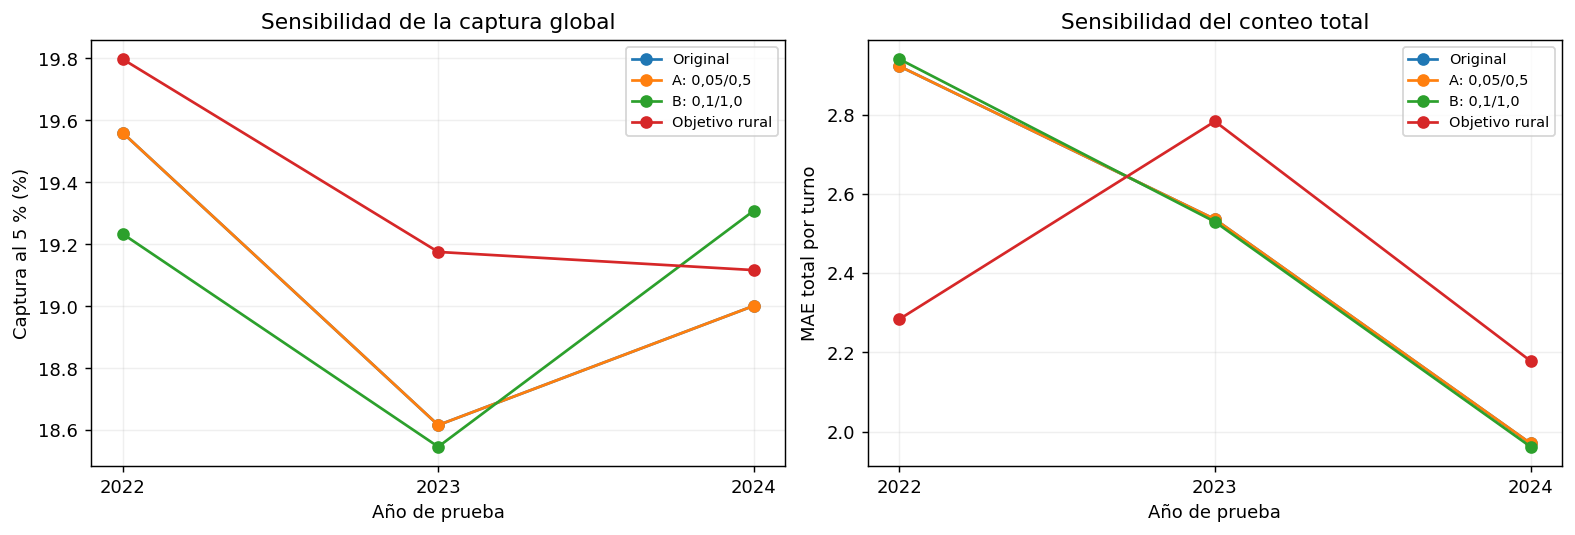

La alternativa B cambia la captura global en **2022: -0.327 pp, 2023: -0.070 pp, 2024: +0.307 pp**. Estos resultados son descriptivos, sin IC para los reajustes de sensibilidad. El objetivo rural cambia la población de entrenamiento; no permite atribuir los cambios al carácter urbano físico del tramo ni sustituye la validación principal.

In [20]:
fig,ax=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for nombre,d in sensibilidad.groupby("escenario",sort=False):
    ax[0].plot(d.anio,d.captura5*100,"o-",label=nombre)
    ax[1].plot(d.anio,d.mae_12h_calendario,"o-",label=nombre)
ax[0].set(title="Sensibilidad de la captura global",ylabel="Captura al 5 % (%)",xticks=[2022,2023,2024])
ax[1].set(title="Sensibilidad del conteo total",ylabel="MAE total por turno",xticks=[2022,2023,2024])
for a in ax:a.set_xlabel("Año de prueba");a.legend(fontsize=8);a.grid(alpha=.2)
mostrar(fig)
base_s=sensibilidad[sensibilidad.escenario=="Original"].set_index("anio")
b_s=sensibilidad[sensibilidad.escenario=="B: 0,1/1,0"].set_index("anio")
diferencia_s=(b_s.captura5-base_s.captura5)*100
r_s=sensibilidad[sensibilidad.escenario=="Objetivo rural"].set_index("anio")
display(Markdown("La alternativa B cambia la captura global en **"+", ".join(f"{a}: {v:+.3f} pp" for a,v in diferencia_s.items())+"**. "
    "Estos resultados son descriptivos, sin IC para los reajustes de sensibilidad. El objetivo rural cambia la población de entrenamiento; "
    "no permite atribuir los cambios al carácter urbano físico del tramo ni sustituye la validación principal."))

## 16. Ampliación investigada a 2025

Se revisaron fuentes CONASET 2025 y se intentó recuperar la pertenencia vial y el
kilometraje mediante geometría MOP, controles de 2024 y direcciones textuales.
La información recuperada no permitió acreditar una cohorte comparable a Ruta 5 Sur.
Una referencia numérica en la dirección no demuestra que su unidad sea km, y una
vía cercana no prueba que el siniestro pertenezca a ella.

Por ello conservamos 2020–2024. No se incorporó una selección parcial de 2025 como
si fuera el año completo. La siguiente tabla resume el diagnóstico de fuentes
realizado durante el proyecto; no participa en el entrenamiento ni en la evaluación
anterior. Esta limitación es de ubicación/comparabilidad, no una demostración de fuga
de información por el mero hecho de usar datos de otro año.

In [21]:
display(pd.read_csv(RAIZ/"resultados/cierre_ubicacion_2025/estados_texto_2025.csv"))
assert eventos.anio.max()==2024
print("Los modelos de esta ejecución utilizan exclusivamente 2020–2024.")

,estado_texto,registros
0,caletera_o_servicio,88
1,comuna_no_coincide,1
2,interseccion,18
3,mencion_sin_numero_interpretable,2
4,referencia_con_numero_sin_unidad_acreditada,2791
5,sin_mencion_literal,66094


Los modelos de esta ejecución utilizan exclusivamente 2020–2024.


## 17. Ejemplo de aplicación a una ventana de 12 horas

La salida del modelo permite sumar tasas horarias por tramo y priorizar una ventana.
A modo de demostración reproducible, usamos las primeras 12 horas de un turno
histórico de prueba y mantenemos 12 tramos enteros. Ese presupuesto es 12/255 =
4,71 %, ligeramente menor que el 5 % fraccionario de las métricas principales.
No se interpreta este ejemplo como una emisión operativa nueva.

El proyecto también implementó un piloto experimental con pronóstico capturado
antes de emitir. Su evaluación futura requiere todos los siniestros observados del
horizonte, con ubicación y hora verificables. No contar con reportes no autoriza a
suponer cero eventos. El notebook acredita modelado retrospectivo y funcionamiento
del mecanismo de priorización, no un servicio operativo validado.

In [22]:
plan12=ejemplo.sort_values(["esperados_12h","km_inicio"],ascending=[False,True]).head(12).copy()
plan12["prioridad"]=np.arange(1,13)
display(plan12[["prioridad","km_inicio","esperados_12h","observados_12h"]].round(5))
print(f"Presupuesto entero: {12/len(referencia):.2%} de los tramos.")
print(f"Conteo esperado de toda la ruta: {mu_turno.sum():.3f}; total observado: {int(y_turno.sum())}.")

,prioridad,km_inicio,esperados_12h,observados_12h
38,1,190,0.13508,1.0
54,2,270,0.10796,0.0
44,3,220,0.10309,0.0
39,4,195,0.10081,0.0
37,5,185,0.08979,0.0
49,6,245,0.08039,0.0
50,7,250,0.07925,0.0
21,8,105,0.07862,0.0
19,9,95,0.07640,1.0
24,10,120,0.06935,0.0


Presupuesto entero: 4.71% de los tramos.
Conteo esperado de toda la ruta: 6.344; total observado: 5.


Para pasar de este ejemplo histórico al piloto de las próximas horas hay que
construir el calendario vigente, capturar un pronóstico meteorológico antes de
emitir y congelar predicciones y prioridades. Cambiar reanálisis por pronóstico y
extrapolar a un año nuevo puede alterar el desempeño; ambas cosas requieren
validación propia. La referencia espacial aproximada tampoco define puntos físicos
de despliegue ni restricciones de traslado del patrullaje.

## 18. Conclusiones calculadas con los resultados de esta ejecución

Las conclusiones siguientes se generan después de entrenar, evaluar y comparar.
Si cambian los resultados al repetir el notebook, el texto numérico cambia con ellos.
La regla de selección y las limitaciones metodológicas permanecen explícitas.

In [23]:
fc=aportes[aportes.aporte=="flujo"]
familias_consistentes=[]
for fam in GRILLAS:
    d=fc[fc.modelo==fam+"_clima_flujo"]
    if len(d)==3 and (d.ic95_inf_pp>0).all():familias_consistentes.append(fam)
texto_flujo=("Ninguna familia tiene un intervalo de aporte del flujo completamente positivo en los tres años."
             if not familias_consistentes else "Las familias con mejora positiva en los tres años son: "+", ".join(familias_consistentes)+".")
texto_sesgo=("sobreestima" if c2024.observado_esperado<1 else "subestima")
conclusiones=f"""
1. **Priorización histórica.** La regla temporal seleccionó **{candidata}**. En 2024 su captura global fue **{c2024.captura5:.2%}**, frente a **{base2024.captura5:.2%}** de M1. La diferencia fue **{intervalo2024.diferencia_pp:.2f} pp**, IC95 % **[{intervalo2024.ic95_inf_pp:.2f}; {intervalo2024.ic95_sup_pp:.2f}]**.
2. **Decisión por turno.** Con ubicación fija durante 12 horas, la candidata capturó **{c2024.captura5_turno:.2%}**. La ganancia global no equivale a la de un patrullaje fijo.
3. **Cantidad esperada.** O/E fue **{c2024.observado_esperado:.3f}**: el modelo {texto_sesgo} el total de ese año. MAE fue **{c2024.mae_12h_calendario:.3f}** siniestros por turno en toda la cohorte. La variante recalibrada obtuvo O/E **{rc2024.observado_esperado:.3f}** y MAE **{rc2024.mae_12h_calendario:.3f}**, sin modificar el ranking.
4. **Circulación.** {texto_flujo} El proxy cubre **{int(datos['cubiertos'].sum())}/{len(referencia)}** tramos; no permite estimar riesgo por vehículo-km ni acreditar disponibilidad histórica de los anexos.
5. **Diagnóstico binario.** Para **{nombre_aux}**, ROC-AUC fue **{bc.roc_auc:.4f}**, AP **{bc.pr_auc_ap:.5f}** y F1 **{bc.f1:.4f}** con umbral de entrenamiento. La referencia siempre-cero tiene accuracy **{bc.accuracy_siempre_cero:.3%}** y recall cero; por eso la accuracy no resume la utilidad para detectar eventos.
6. **Robustez y alcance.** Las sensibilidades se muestran con sus métricas y no se usan para reseleccionar con 2024. La discontinuidad de etiquetas urbanas limita su interpretación. Los resultados describen Ruta 5 Sur 2020–2024; no validan otras rutas, 2025 ni un servicio predictivo operativo.
"""
display(Markdown(conclusiones))


1. **Priorización histórica.** La regla temporal seleccionó **Poisson_clima**. En 2024 su captura global fue **19.00%**, frente a **14.89%** de M1. La diferencia fue **4.11 pp**, IC95 % **[2.10; 6.08]**.
2. **Decisión por turno.** Con ubicación fija durante 12 horas, la candidata capturó **15.84%**. La ganancia global no equivale a la de un patrullaje fijo.
3. **Cantidad esperada.** O/E fue **0.772**: el modelo sobreestima el total de ese año. MAE fue **1.970** siniestros por turno en toda la cohorte. La variante recalibrada obtuvo O/E **1.154** y MAE **1.684**, sin modificar el ranking.
4. **Circulación.** Ninguna familia tiene un intervalo de aporte del flujo completamente positivo en los tres años. El proxy cubre **153/255** tramos; no permite estimar riesgo por vehículo-km ni acreditar disponibilidad histórica de los anexos.
5. **Diagnóstico binario.** Para **Poisson_clima**, ROC-AUC fue **0.7103**, AP **0.00364** y F1 **0.0077** con umbral de entrenamiento. La referencia siempre-cero tiene accuracy **99.886%** y recall cero; por eso la accuracy no resume la utilidad para detectar eventos.
6. **Robustez y alcance.** Las sensibilidades se muestran con sus métricas y no se usan para reseleccionar con 2024. La discontinuidad de etiquetas urbanas limita su interpretación. Los resultados describen Ruta 5 Sur 2020–2024; no validan otras rutas, 2025 ni un servicio predictivo operativo.


### Limitaciones y próximos pasos

El reanálisis meteorológico no acredita un pronóstico disponible en la fecha de
decisión. El proxy de circulación no reemplaza la exposición real. Las etiquetas
urbanas cambian entre períodos y la asignación vial de 2025 no quedó resuelta.
La evaluación de 2024 es histórica reutilizada, no una prueba intacta. Los intervalos
mantienen fijas las predicciones y no corrigen múltiples comparaciones.

El siguiente paso científico es evaluar con un año nuevo correctamente ubicado y
con fuentes disponibles antes de decidir, incluyendo exposición vehicular acreditada.
Para el despliegue se necesitan observaciones completas, calendario actualizado,
pronósticos emitidos y evaluación prospectiva. No se deducen causalidad, riesgo
individual ni siniestros evitados de estos resultados.

### Referencias y reproducibilidad

- CONASET: Observatorio de Datos y Estadística y registros geográficos de siniestros.
- Open-Meteo: ERA5 Historical Weather API, precipitación horaria.
- Dirección General de Concesiones: anexos trimestrales 2023T4 y 2024T4.
- MOP/Vialidad: Plan Nacional de Censos Viales y límites de contratos citados en el código.
- Pauta del curso, **Proyecto Semestral de Data Science**, Etapa III: comparación,
  selección, validación con métricas apropiadas, interpretación y conexión con el problema.
- Documentación de scikit-learn: [evaluación de modelos](https://scikit-learn.org/stable/modules/model_evaluation.html).

Los archivos incorporados tienen sus hashes en `MANIFIESTO_ENTREGA.json`; la corrida
registra parámetros, búsqueda, selección, diagnósticos, versiones y artefactos.
El código y los datos extraídos se pueden inspeccionar sin credenciales personales.
Para repetir todo el trabajo, reiniciar el kernel y ejecutar el notebook completo.

In [24]:
for nombre,sha in manifest["archivos_sha256"].items():
    assert hashlib.sha256((RAIZ/nombre).read_bytes()).hexdigest()==sha,nombre
assert len(busqueda)==60 and len(metricas)==114 and len(seleccion)==36
assert candidata==reajuste["modelo"]
assert all(a.get("convergio",True) for a in auditoria["ajustes"]+reajuste["ajustes"])
reproduccion={"entrenamiento_completo":True,"configuraciones_ajustadas":len(busqueda),
    "familias":list(GRILLAS),"metricas_calculadas":len(metricas),"modelo_seleccionado":candidata,
    "reajuste_final_sin_prueba_futura":True,"datos_incorporados_verificados":True,
    "minutos_entrenamiento":round(minutos_ajuste,2),
    "directorio_resultados":str(SALIDA),"fecha_ejecucion_utc":pd.Timestamp.now(tz="UTC").isoformat(),
    "modelos_preajustados_incorporados":False,"sha256_paquete":hashlib.sha256(paquete).hexdigest(),
    "versiones":{n:metadata.version(n) for n in ["numpy","pandas","scipy","scikit-learn","matplotlib","joblib"]}}
(SALIDA/"resumen_ejecucion.json").write_text(json.dumps(reproduccion,ensure_ascii=False,indent=2)+"\n")
display(JSON(reproduccion))
print("CIERRE_NOTEBOOK_CORRECTO: modelos entrenados, comparaciones y conclusiones calculadas.")

<IPython.core.display.JSON object>

CIERRE_NOTEBOOK_CORRECTO: modelos entrenados, comparaciones y conclusiones calculadas.
